# 11 — Animasi orbit 3D (GIF dan MP4)

Model kampus `output/ui_lod2.glb` (notebook 07) dirender ulang dengan PyVista lalu kamera diputar
360° mengelilingi pusat kampus. Hasilnya bisa langsung dipakai di slide atau media sosial.

1. Muat GLB dengan `trimesh`, ubah sumbu glTF (Y ke atas) ke Z ke atas.
2. Ubah tiap mesh ke `pyvista.PolyData`, bawa tekstur citra (terrain, dinding) dan warna vertex (atap, jalan, air).
3. Lintasan kamera: lingkaran berjari-jari `R` pada ketinggian `Z`, menatap pusat gedung.
4. Tulis frame ke GIF (`open_gif`) dan MP4 (`open_movie`).

PyVista punya `generate_orbital_path` + `orbit_on_path`, tetapi di sini kamera diatur sendiri per frame
agar jari-jari dan ketinggian dalam meter terlihat jelas dan mudah diubah.

**Output**: `output/ui_orbit.gif`, `output/ui_orbit.mp4`, `figures/fig26_orbit_frames.png`.

In [1]:
from pathlib import Path

import numpy as np
import pyvista as pv
import trimesh
from PIL import Image

from ui3d_common import fig_path, out

pv.OFF_SCREEN = True  # render tanpa jendela (juga jalan di server)

GLB = out("ui_lod2.glb")
R, Z = 1100, 600            # jari-jari dan tinggi kamera (m) dari pusat kampus
N_GIF, N_MP4 = 48, 180      # jumlah frame: GIF 4 s @12 fps, MP4 12 s @15 fps
GIF_SIZE, MP4_SIZE = (800, 450), (1280, 720)  # piksel; GIF dibuat kecil agar < 15 MB

## 1–2. GLB → PyVista

glTF memakai sumbu `x` = timur, `y` = atas, `z` = selatan. Matriks `YUP_TO_ZUP` memutar −90° di sumbu x
sehingga `z` = atas dan `y` = utara, sesuai konvensi peta.

In [2]:
YUP_TO_ZUP = np.array([[1, 0, 0, 0], [0, 0, -1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], float)


def to_pv(g):
    """trimesh.Trimesh → (pv.PolyData, argumen add_mesh) dengan tekstur atau warna vertex."""
    g = g.copy()
    g.apply_transform(YUP_TO_ZUP)
    m = pv.wrap(g)
    if g.visual.kind == "texture":
        m.active_texture_coordinates = np.asarray(g.visual.uv, "float32")
        img = np.asarray(g.visual.material.baseColorTexture.convert("RGB"))
        return m, dict(texture=pv.Texture(img))
    if g.visual.kind == "vertex":
        m.point_data["rgb"] = np.asarray(g.visual.vertex_colors)[:, :3]
        return m, dict(scalars="rgb", rgb=True)
    return m, dict(color="lightgray")


meshes = {}
for g in trimesh.load(GLB).dump():
    meshes[g.metadata.get("name", f"mesh{len(meshes)}")] = to_pv(g)
for k, (m, kw) in meshes.items():
    print(f"{k:10s} {m.n_points:>8,} titik  {m.n_cells:>8,} sel  {'tekstur' if 'texture' in kw else 'warna'}")

doors         7,960 titik    11,940 sel  warna
windows     354,192 titik   531,288 sel  warna
roofs         5,315 titik     3,337 sel  warna
walls       252,272 titik   126,136 sel  tekstur
water         3,992 titik     3,956 sel  warna
roads        53,302 titik    46,285 sel  warna
terrain_context  216,468 titik   429,500 sel  tekstur
terrain      82,200 titik   163,180 sel  tekstur


## 3. Lintasan kamera

Pusat orbit = median titik atap, bukan pusat terrain, karena terrain melebar 3 km ke utara–selatan
sedangkan gedung terkumpul di tengah kampus.

In [3]:
fx, fy = np.median(meshes["roofs"][0].points[:, :2], axis=0)
FOCUS = (fx, fy, 60)


def orbit(n):
    a = np.linspace(0, 2 * np.pi, n, endpoint=False)  # mulai dari selatan, berputar berlawanan jarum jam
    return np.c_[fx + R * np.sin(a), fy - R * np.cos(a), np.full(n, Z)]


def make_plotter(size):
    p = pv.Plotter(window_size=size)
    p.set_background("#f4f1ea", top="#8fb8de")  # gradasi langit; tepi terrain tidak lagi berbatasan putih polos
    for m, kw in meshes.values():
        p.add_mesh(m, **kw)
    return p


def render(path, size, open_fn, *args, **kw):
    p = make_plotter(size)
    getattr(p, open_fn)(*args, **kw)
    for pos in path:
        p.camera_position = [tuple(pos), FOCUS, (0, 0, 1)]
        p.renderer.ResetCameraClippingRange()
        p.write_frame()
    p.close()


print(f"Pusat orbit: {FOCUS[0]:.0f}, {FOCUS[1]:.0f} m (lokal); jarak pandang {np.hypot(R, Z - FOCUS[2]):.0f} m")

Pusat orbit: 18, -107 m (lokal); jarak pandang 1225 m


## 4. GIF dan MP4

GIF praktis untuk slide tetapi boros: tiap frame disimpan utuh dengan 256 warna, jadi resolusinya dibuat kecil.
MP4 (H.264 lewat `imageio-ffmpeg`) memampatkan antar-frame, jadi resolusi 720p tetap ringan.
`quality` 0–10 mengatur kompresi MP4: makin tinggi, makin tajam dan makin besar.

In [4]:
render(orbit(N_GIF), GIF_SIZE, "open_gif", out("ui_orbit.gif"), fps=12, subrectangles=True)
render(orbit(N_MP4), MP4_SIZE, "open_movie", out("ui_orbit.mp4"), framerate=15, quality=5)
for f in ("ui_orbit.gif", "ui_orbit.mp4"):
    print(f, f"{Path(out(f)).stat().st_size / 1e6:.1f} MB")

ui_orbit.gif 16.8 MB
ui_orbit.mp4 12.7 MB


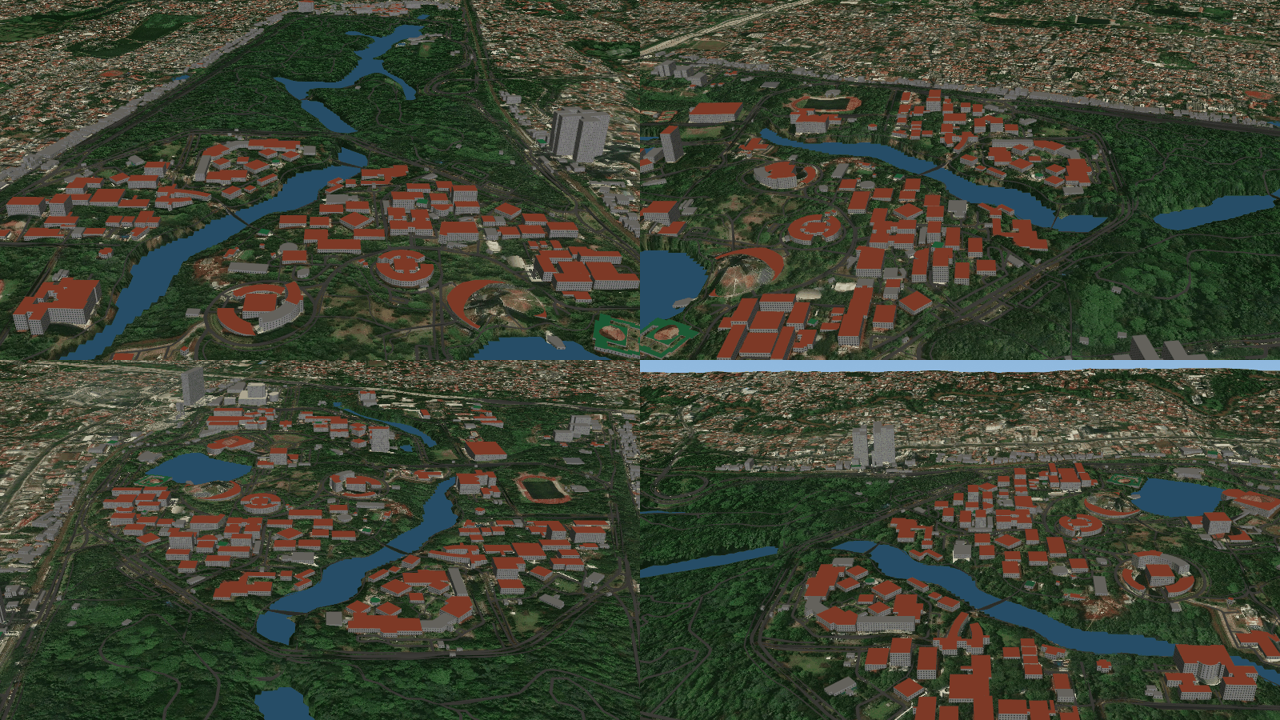

In [5]:
import imageio.v3 as iio

frames = iio.imread(out("ui_orbit.gif"), index=None)
sheet = Image.new("RGB", (1280, 720))
for k, i in enumerate(np.linspace(0, len(frames), 4, endpoint=False).astype(int)):
    sheet.paste(Image.fromarray(frames[i][..., :3]).resize((640, 360)), ((k % 2) * 640, (k // 2) * 360))
sheet.save(fig_path("fig26_orbit_frames.png"))
sheet